# Propagating Strain Pulses

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/03-phonons/01-strain_pulses.ipynb)

In this example coherent acoustic phonon dynamics are calculated according to the results of the {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` simulations.

:::{admonition} Reference {cite}`herzog2012`
:class: seealso
M. Herzog, et al., *Analysis of ultrafast X-ray diffraction data in a linear-chain model of the lattice dynamics*,
[Applied Physics A, 106(3), 489-499 (2011)](https://doi.org/10.1007/s00339-011-6719-z)
:::

:::{admonition} Reference {cite}`bojahr2012`
:class: seealso
A. Bojahr, et al., *Calibrated real-time detection of nonlinearly propagating strain waves*,
[Phys. Rev. B, 86(14), 144306 (2012)](http://www.doi.org/10.1103/PhysRevB.86.144306)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In [2]:
O = ud.Atom("O")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")
Pb = ud.Atom("Pb")
Zr = ud.Atom("Zr")

In [3]:
# c-axis lattice constants of the two layers
c_STO_sub = 3.905 * u.angstrom
c_SRO = 3.94897 * u.angstrom

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=ud.ThermalParameters(
        therm_cond=5.72 * u.W / (u.m * u.K),
        lin_therm_exp=1.03e-5,
        heat_capacity="455.2 + 0.112*T - 2.1935e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=6.312 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.44 + 4.32j)),
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

# STO substrate
STO_sub = ud.UnitCell(
    "STOsub",
    "Strontium Titanate Substrate",
    lattice=ud.LatticeParameters(c_axis=c_STO_sub),  # a- and b-axis default to the c-axis
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO_sub.add_atom(O, 0)
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

In [4]:
S = ud.Structure("Single Layer")
S.add_sub_structure(SRO, 100)  # add 100 layers of SRO to sample
S.add_sub_structure(STO_sub, 2000)  # add 2000 layers of STO substrate

# add semi-infinite, static substrate
S.add_substrate(STO_sub)

## Heat

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [5]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h.excitation = {
    "fluence": [5] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}

# temporal and spatial grid
delays = np.r_[-10:90:0.1] * u.ps
_, _, distances = S.get_distances_of_layers()

In [6]:
temp_map, delta_temp_map = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 56.1 % and transmission of 5.7 %.
Elapsed time for _temperature_after_delta_excitation_: 0.187399 s
Elapsed time for _temp_map_: 0.279373 s


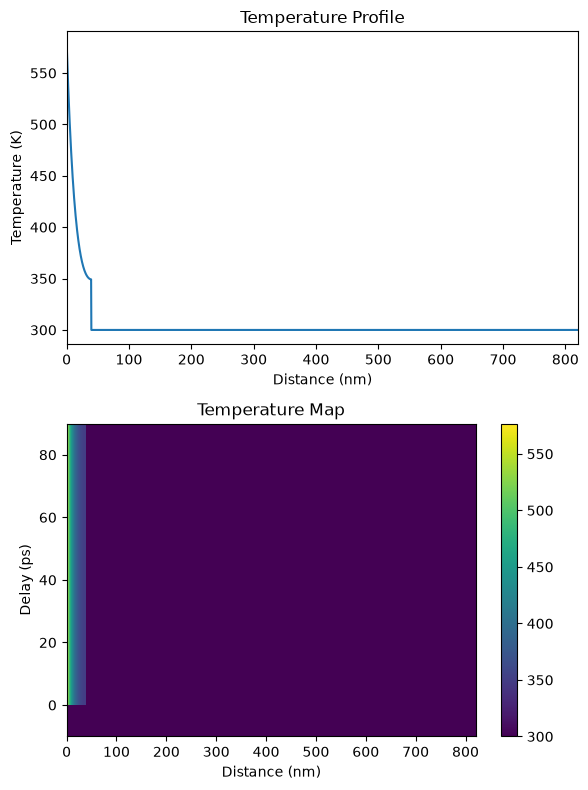

In [7]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, temp_map[101, :])
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.title("Temperature Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map, shading="auto")
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map")

plt.tight_layout()
plt.show()

## Analytical Phonons

The {py:class}`PhononAna <udkm1Dsim.simulations.phonons.PhononAna>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can using the boolean switch `progress_bar`.

In [8]:
pana = ud.PhononAna(S, True)
pana.save_data = False
pana.disp_messages = True

In [9]:
strain_map, A, B = pana.get_strain_map(delays, temp_map, delta_temp_map)

Calculating linear thermal expansion ...
Calculating _eigen_values_ ...
Elapsed time for _eigen_values_: 0.754253 s
Calculating _strain_map_ ...


Progress:   0%|          | 0/1000 [00:00<?, ?it/s]

Elapsed time for _strain_map_: 2.129767 s


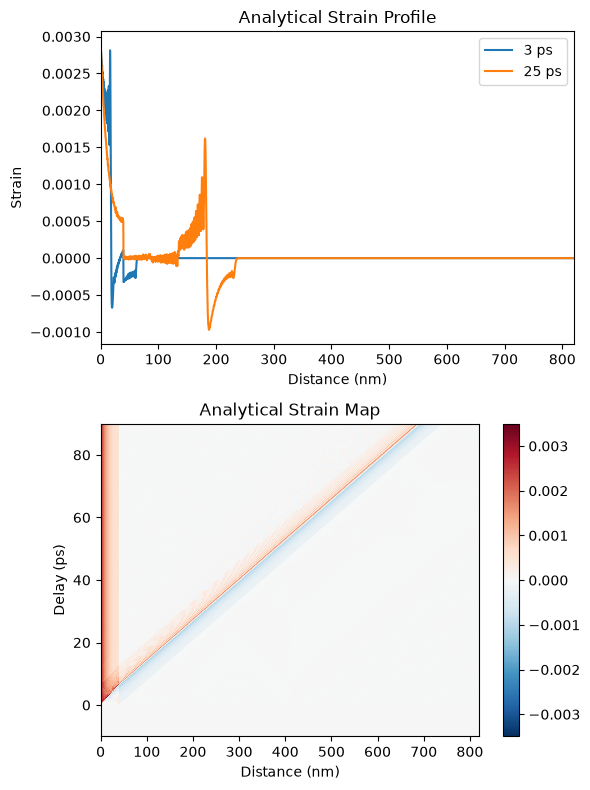

In [10]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, strain_map[130, :], label=np.round(delays[130]))
plt.plot(distances.to("nm").magnitude, strain_map[350, :], label=np.round(delays[350]))
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Analytical Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    strain_map,
    cmap="RdBu_r",
    vmin=-np.max(strain_map),
    vmax=np.max(strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Analytical Strain Map")

plt.tight_layout()
plt.show()

### Energy Spectrum

The analytical phonon model easily allows for calculating the energy per eigenmode of the coherent acoustic phonon spectrum for every delay of the simulation.
As the masses of the layers are normalized to an area of 1 Å², the energy is given per 1 Å² of the sample.
The free surface and backside of the sample result in an eigenmode with zero frequency, i.e. a translation of the whole sample, which is not shown on the logarithmic frequency axis.

In [11]:
omega, E = pana.get_energy_per_eigenmode(A, B)

Calculating _eigen_values_ ...
Elapsed time for _eigen_values_: 0.674276 s


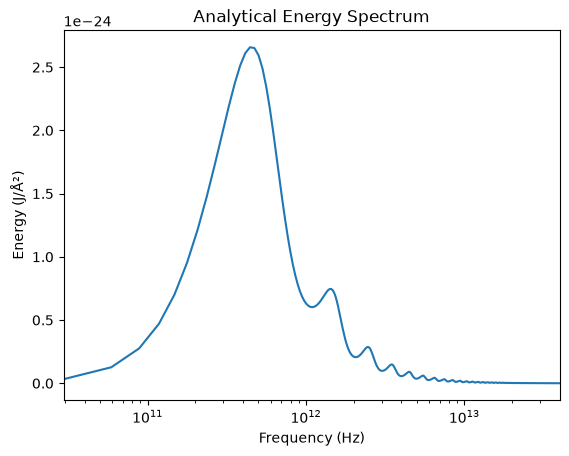

In [12]:
select = omega > 0  # without the translation of the whole sample

plt.figure()
plt.plot(omega[select], E[-1, select])
plt.xscale("log")
plt.xlim(omega[select][0], omega[-1])
plt.xlabel("Frequency (Hz)")
plt.ylabel("Energy (J/Å²)")
plt.title("Analytical Energy Spectrum")
plt.show()

## Numerical Phonons

The {py:class}`PhononNum <udkm1Dsim.simulations.phonons.PhononNum>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can using the boolean switch `progress_bar`.

In [13]:
pnum = ud.PhononNum(S, True)
pnum.save_data = False
pnum.disp_messages = True

The actual calculation is done in one line:

In [14]:
strain_map = pnum.get_strain_map(delays, temp_map, delta_temp_map)

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 1.446886 s


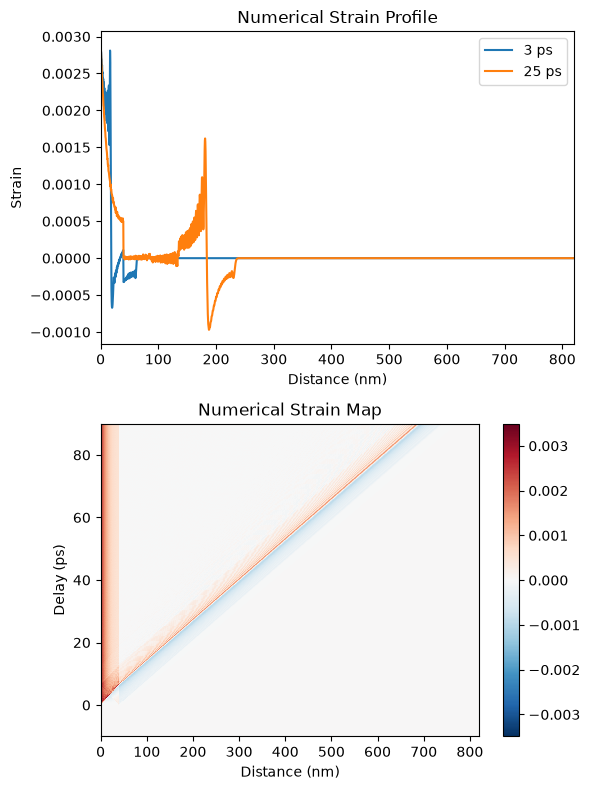

In [15]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, strain_map[130, :], label=np.round(delays[130]))
plt.plot(distances.to("nm").magnitude, strain_map[350, :], label=np.round(delays[350]))
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Numerical Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    strain_map,
    cmap="RdBu_r",
    vmin=-np.max(strain_map),
    vmax=np.max(strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Numerical Strain Map")

plt.tight_layout()
plt.show()

## Anharmonic Phonon Propagation
example_anharmonic_linear_chain

The numerical phonon dynamic calculations also allow for phonon damping and non-linear phonon propagation.
This can be achieved by setting the `phonon_damping` property and using the {py:meth}`set_ho_spring_constants <udkm1Dsim.structures.layers.Layer.set_ho_spring_constants>` method of the according layers.
The `phonon_damping` acts as dashpot between neighbouring layers, so that the damping rate of a phonon grows with the square of its wave vector.

:::{versionchanged} 3.0.0a2
The `phonon_damping` acts on the rate of deformation between neighbouring layers instead of the velocity of each layer and must be positive.
:::

In [16]:
STO_sub.phonon_damping = 2e-13 * u.kg / u.s
STO_sub.set_ho_spring_constants([-3e12])

Recalculate the coherent phonon dynamics:

In [17]:
strain_map = pnum.get_strain_map(delays, temp_map, delta_temp_map)

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 5.177529 s


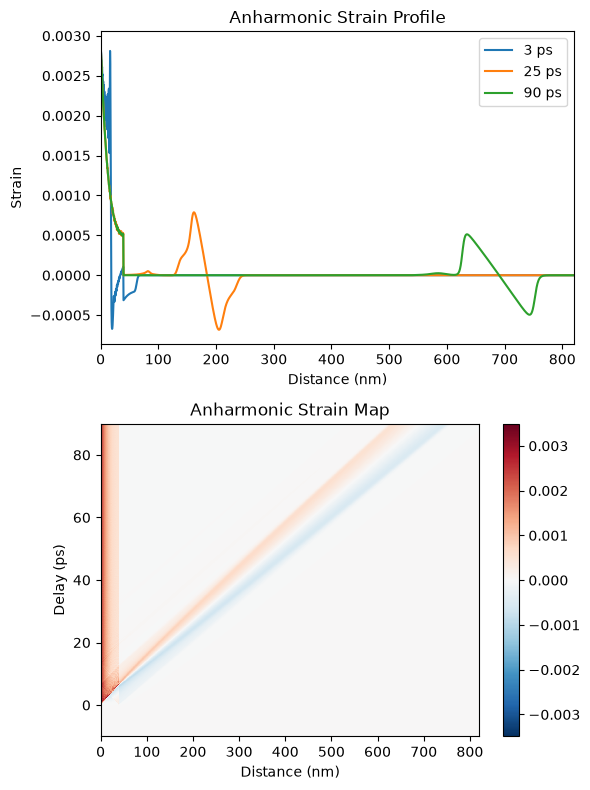

In [18]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(distances.to("nm").magnitude, strain_map[130, :], label=np.round(delays[130]))
plt.plot(distances.to("nm").magnitude, strain_map[350, :], label=np.round(delays[350]))
plt.plot(distances.to("nm").magnitude, strain_map[-1, :], label=np.round(delays[-1]))
plt.xlim([0, distances.to("nm").magnitude[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Anharmonic Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude,
    delays.to("ps").magnitude,
    strain_map,
    cmap="RdBu_r",
    vmin=-np.max(strain_map),
    vmax=np.max(strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Anharmonic Strain Map")

plt.tight_layout()
plt.show()